# HelpDesk Analytics · Análisis exploratorio

**Notebook 01 | Python · Pandas · NumPy · Matplotlib**

De los registros a las preguntas: volumen, calidad, prioridades, resoluciones y evolución temporal.

Este documento combina explicaciones, cálculos reproducibles y cuatro gráficos. Las salidas se conservan para su lectura en GitHub. Para reproducirlo, utiliza el entorno **`.venv`** del proyecto y ejecuta todas las celdas en orden, desde un kernel reiniciado.

**Alcance:** análisis descriptivo de una extracción histórica. No conecta a SQL Server, no ejecuta el ETL y no modifica datos ni Power BI. Los datos procesados deben estar disponibles localmente; no se distribuyen en Git.

## 1. Introducción

### Objetivo y preguntas

Explorar los tickets y su historial para responder: ¿qué volumen se conserva?, ¿qué ausencias y anomalías existen?, ¿cómo se distribuyen prioridades y resoluciones?, ¿cómo cambia la creación de tickets en el tiempo?

La unidad principal es el **ticket**. Un **evento** representa un cambio de campo; varios eventos pueden pertenecer al mismo ticket. No deben sumarse ambos volúmenes como si fueran entidades equivalentes. Además, «ticket» designa aquí registros de varios tipos, incluidos `Ticket`, `Service`, `Story` y otros usos del sistema.

### Fuente, licencia y documentación

- **Dataset:** Mohammad Abdellatif, *Help Desk Tickets*, versión 3, Mendeley Data; [DOI 10.17632/btm76zndnt.3](https://doi.org/10.17632/btm76zndnt.3).
- **Licencia del dataset:** [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/). La atribución completa está en [README](../README.md#fuente-de-datos-y-atribución).
- **Definiciones del proveedor:** [data/FEATURES.md](../data/FEATURES.md).
- **Evidencia del proyecto:** [calidad de datos](../reports/data_quality.md), [exploración SQL](../reports/sql_exploration.md) e [informe final](../reports/final_analysis.md).

Se utilizan los dos CSV **procesados**, conservando sus filas, nulos, categorías y flags. La documentación describe tickets desde 2016, pero los registros incluyen creaciones anteriores: esa diferencia se investigará sin eliminar datos. No se presupone que tener historial signifique disponer de todas las transiciones.

### Recorrido

1. Introducción y fuentes.
2. Librerías y estilo visual.
3. Rutas, carga y referencias.
4. Exploración inicial.
5. Calidad de datos.
6. Prioridades.
7. Resoluciones.
8. Evolución temporal.
9. Hallazgos y validaciones.
10. Conclusiones.

**Herramientas:** Pandas para tablas; NumPy para comparaciones numéricas y etiquetas de períodos; Matplotlib para gráficos; Jupyter/IPython para ejecutar y presentar el análisis. Python estándar se utiliza para rutas, huellas de archivos y lectura de las tablas de referencia.

## 2. Importación de librerías

Se usa una paleta consistente: azul para volumen, verde azulado para la resolución `Done`, naranja para información desconocida o períodos parciales y gris para ausencia de resolución. La escala es lineal y comienza en cero para facilitar la comparación de cantidades.

Las funciones de presentación limitan las salidas y utilizan separadores numéricos en español. Las versiones se registran sin mostrar rutas del intérprete ni variables de entorno.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import re
import sys

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import HTML, Markdown, display

PALETA = {
    "azul": "#245C83", "verde": "#168477", "naranja": "#BA6515",
    "gris": "#77838F", "texto": "#203341", "rejilla": "#E2E8ED",
}
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelcolor": PALETA["texto"], "text.color": PALETA["texto"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "grid.color": PALETA["rejilla"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "figure.facecolor": "white",
    "axes.facecolor": "white", "figure.dpi": 110,
    "savefig.dpi": 125, "savefig.bbox": "tight",
})
pd.set_option("display.max_rows", 16)
pd.set_option("display.max_columns", 8)

def numero_es(valor, decimales=0):
    return f"{valor:,.{decimales}f}".translate(str.maketrans({",": ".", ".": ","}))

def mostrar_tabla(tabla, decimales=2):
    """Mostrar tablas acotadas; nunca una tabla completa de tickets o eventos."""
    if len(tabla) > 20 or len(tabla.columns) > 9:
        raise ValueError("Reduce explícitamente la tabla antes de publicarla.")
    formatos = {
        c: (lambda v: numero_es(v, decimales))
        for c in tabla.select_dtypes(include="floating").columns
    }
    formatos.update({
        c: (lambda v: numero_es(v))
        for c in tabla.select_dtypes(include="integer").columns
    })
    display(HTML(tabla.to_html(index=False, border=0, na_rep="—", formatters=formatos)))

versiones = {"Python": sys.version.split()[0], "Pandas": pd.__version__,
             "NumPy": np.__version__, "Matplotlib": mpl.__version__}
versiones.update({nombre: importlib.metadata.version(nombre)
                  for nombre in ["ipykernel", "nbformat", "nbclient"]})
mostrar_tabla(pd.DataFrame(versiones.items(), columns=["Herramienta", "Versión"]))

Herramienta,Versión
Python,3.13.2
Pandas,2.3.3
NumPy,2.5.4
Matplotlib,3.11.2
ipykernel,7.4.0
nbformat,5.11.1
nbclient,0.11.0


## 3. Carga de datos

La raíz se localiza recorriendo el directorio actual y sus padres. Así funciona al iniciar desde la raíz o desde `notebooks/`, sin rutas absolutas del equipo. Se comprueba que el kernel pertenezca a `.venv`.

Se reutiliza **`read_csv` de `src/clean_data.py`**, sin llamar al proceso de limpieza. Su contrato lee las columnas como texto y reconoce como nulo sólo un campo vacío. Por ello `unknown`, `NA` o `null`, si existen como texto, no se convierten automáticamente en ausencias.

Las huellas SHA-256 se calculan antes y después del análisis para verificar que los archivos procesados permanecen intactos. No se imprimen rutas personales.

In [2]:
def encontrar_raiz(inicio):
    for candidato in [inicio, *inicio.parents]:
        if ((candidato / "src/clean_data.py").is_file()
                and (candidato / "requirements.txt").is_file()
                and (candidato / "reports/sql_exploration.md").is_file()):
            return candidato
    raise FileNotFoundError("Abre el notebook dentro de la carpeta del proyecto.")

RAIZ = encontrar_raiz(Path.cwd().resolve())
if Path(sys.prefix).resolve() != (RAIZ / ".venv").resolve():
    raise RuntimeError("Selecciona el kernel del entorno .venv de este proyecto.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.clean_data import read_csv

ARCHIVOS = {
    "Tickets": RAIZ / "data/processed/issues_clean.csv",
    "Eventos": RAIZ / "data/processed/issues_change_history_clean.csv",
}
for ruta in ARCHIVOS.values():
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta el archivo procesado {ruta.name}; consulta README.")
for relativo in ["reports/data_quality.md", "reports/final_analysis.md", "data/FEATURES.md"]:
    if not (RAIZ / relativo).is_file():
        raise FileNotFoundError(f"Falta la referencia del proyecto: {relativo}")

def huella(ruta):
    with ruta.open("rb") as archivo:
        return hashlib.file_digest(archivo, "sha256").hexdigest()

huellas_iniciales = {nombre: huella(ruta) for nombre, ruta in ARCHIVOS.items()}
tickets = read_csv(ARCHIVOS["Tickets"])
eventos = read_csv(ARCHIVOS["Eventos"])
print("Kernel .venv verificado. Dos CSV procesados cargados en modo de lectura.")

Kernel .venv verificado. Dos CSV procesados cargados en modo de lectura.


### Referencias verificables y control de discrepancias

Se leen las tablas Markdown del informe SQL existente. No se requiere conexión al servidor. Las comparaciones validan conteos exactos y porcentajes con la tolerancia necesaria para el redondeo SQL a cuatro decimales porcentuales.

Si una comprobación falla, la ejecución se detiene: debe investigarse si cambiaron los datos, la referencia o la definición. **No se modifican cifras para forzar coincidencias.** Las comprobaciones se resumen en la sección 9.

In [3]:
controles = []

def verificar(nombre, condicion, detalle):
    if not bool(condicion):
        raise AssertionError(f"Discrepancia: {nombre}. Revisa los datos y la referencia.")
    controles.append({"Control": nombre, "Estado": "SUPERADA", "Alcance": detalle})

def tablas_documentadas(archivo, encabezado):
    """Leer tablas de una sección concreta; no ejecutar scripts ni consultas SQL."""
    texto = (RAIZ / archivo).read_text(encoding="utf-8")
    patron = rf"^## {encabezado}[^\n]*\n(.*?)(?=^## |\Z)"
    bloque = re.search(patron, texto, flags=re.M | re.S)
    if bloque is None:
        raise ValueError("No se encuentra la sección esperada de la referencia.")
    tablas, filas = [], []
    for linea in [*bloque.group(1).splitlines(), ""]:
        if linea.startswith("|"):
            filas.append([celda.strip() for celda in linea.strip("|").split("|")])
        elif filas:
            tablas.append(pd.DataFrame(filas[2:], columns=filas[0]))
            filas = []
    if not tablas:
        raise ValueError("La sección no contiene una tabla verificable.")
    return tablas

def tabla_sql(seccion):
    return tablas_documentadas("reports/sql_exploration.md", rf"{seccion}\.")[0]

def frecuencias(serie, nombre="Categoría"):
    conteos = serie.value_counts(dropna=False)
    conteos.index = conteos.index.fillna("Sin resolución registrada")
    salida = conteos.rename_axis(nombre).rename("Tickets").reset_index()
    salida["Porcentaje (%)"] = 100 * salida["Tickets"] / len(serie)
    return salida.sort_values(["Tickets", nombre], ascending=[False, True]).set_index(nombre)

def validar_distribucion(actual, seccion, nombre):
    referencia = tabla_sql(seccion)
    indice = referencia.iloc[:, 0].replace({"(NULL)": "Sin resolución registrada"}).astype(str)
    if seccion == "G":
        # SQL representa cada mes con su primer día; el análisis usa AAAA-MM.
        indice = indice.str.slice(0, 7)
    esperado = pd.DataFrame({
        "Tickets": pd.to_numeric(referencia["cantidad"]).to_numpy(),
        "Porcentaje (%)": pd.to_numeric(referencia["porcentaje_total"]).to_numpy(),
    }, index=indice)
    observado = actual[["Tickets", "Porcentaje (%)"]].copy()
    observado.index = observado.index.astype(str)
    observado = observado.sort_index()
    esperado = esperado.sort_index()
    mismos_grupos = observado.index.equals(esperado.index)
    verificar(f"{nombre}: conteos SQL", mismos_grupos and
              np.array_equal(observado["Tickets"].to_numpy(), esperado["Tickets"].to_numpy()),
              f"{len(esperado)} grupos; consulta {seccion}")
    verificar(f"{nombre}: porcentajes SQL", mismos_grupos and
              np.allclose(observado["Porcentaje (%)"], esperado["Porcentaje (%)"],
                          atol=0.00005, rtol=0), "Tolerancia: 0,00005 puntos porcentuales")

## 4. Exploración inicial

### Tamaño, tipos y granularidad

`shape` informa filas y columnas de cada archivo completo, incluidas las columnas de calidad y trazabilidad. Los CSV no almacenan tipos: el lector aplica `string` deliberadamente. A continuación se crea una **vista analítica en memoria** con fechas UTC y tres conteos numéricos, sin alterar los DataFrames de origen ni los archivos.

Los identificadores permanecen como texto para evitar conversiones aproximadas. Las duraciones originales no se convierten ni se corrigen en este notebook.

In [4]:
resumen_archivos = pd.DataFrame([
    {"Dataset": nombre, "Filas": len(df), "Columnas": len(df.columns),
     "Tipo de lectura": ", ".join(sorted(set(df.dtypes.astype(str))))}
    for nombre, df in [("Tickets", tickets), ("Eventos", eventos)]
])
mostrar_tabla(resumen_archivos)
referencia_volumen = tabla_sql("A").set_index("dataset")["cantidad"].astype(int)
verificar("Volúmenes SQL", len(tickets) == referencia_volumen["tickets"] and
          len(eventos) == referencia_volumen["eventos"], "Consulta A; tickets y eventos separados")

campos_analisis = ["issue_priority", "issue_type", "issue_status", "issue_resolution",
                   "issue_created", "issue_resolution_date", "issue_comments_count",
                   "issue_contr_count", "processing_steps"]
analisis = tickets[campos_analisis].copy()
for columna in ["issue_created", "issue_resolution_date"]:
    analisis[columna] = pd.to_datetime(analisis[columna], utc=True, format="ISO8601", errors="raise")
conteos_numericos = ["issue_comments_count", "issue_contr_count", "processing_steps"]
for columna in conteos_numericos:
    analisis[columna] = pd.to_numeric(analisis[columna], errors="raise").astype("Int64")
creacion_eventos = pd.to_datetime(eventos["created"], utc=True, format="ISO8601", errors="raise")
mostrar_tabla(pd.DataFrame({"Campo analítico": analisis.columns,
                            "Tipo en memoria": analisis.dtypes.astype(str).to_numpy()}))

Dataset,Filas,Columnas,Tipo de lectura
Tickets,66.691,102,string
Eventos,257.508,28,string


Campo analítico,Tipo en memoria
issue_priority,string
issue_type,string
issue_status,string
issue_resolution,string
issue_created,"datetime64[ns, UTC]"
issue_resolution_date,"datetime64[ns, UTC]"
issue_comments_count,Int64
issue_contr_count,Int64
processing_steps,Int64


### Primeros registros: selección acotada para publicación

Se muestran cinco filas en el orden del archivo, con categorías y fechas de día en UTC. Se excluyen IDs, proyectos, usuarios, valores de asignación y columnas `__raw`. Esta vista no es una muestra aleatoria ni permite generalizar sobre toda la población.

In [5]:
muestra_tickets = analisis.head(5)[[
    "issue_type", "issue_priority", "issue_status", "issue_resolution", "issue_created"
]].copy()
muestra_tickets["issue_created"] = muestra_tickets["issue_created"].dt.strftime("%Y-%m-%d")
muestra_tickets.columns = ["Tipo", "Prioridad", "Estado final", "Resolución", "Creación (UTC)"]
mostrar_tabla(muestra_tickets)
muestra_eventos = pd.DataFrame({
    "Campo modificado": eventos["field"].head(5),
    "Fecha del evento (UTC)": creacion_eventos.head(5).dt.strftime("%Y-%m-%d"),
})
mostrar_tabla(muestra_eventos)

Tipo,Prioridad,Estado final,Resolución,Creación (UTC)
Ticket,Medium,done,Done,2016-01-06
Ticket,Medium,done,Done,2016-01-11
Ticket,Medium,done,Done,2016-01-21
Vacation,Medium,done,Done,2016-01-26
Story,Medium,done,Done,2016-02-01


Campo modificado,Fecha del evento (UTC)
status,2016-03-24
status,2016-03-24
status,2016-03-24
status,2016-03-24
status,2016-03-24


### Estadísticas descriptivas

`describe` resume tres conteos por ticket: comentarios, colaboradores y pasos registrados. Se incluyen mediana y P90 para complementar la media y el máximo. No se interpretan como horas trabajadas ni como productividad; un paso registrado tampoco equivale a una interacción independiente con el usuario.

In [6]:
nombres_conteos = {"issue_comments_count": "Comentarios por ticket",
                   "issue_contr_count": "Colaboradores registrados por ticket",
                   "processing_steps": "Pasos registrados por ticket"}
descriptivas = analisis[conteos_numericos].describe(percentiles=[0.5, 0.9]).T
descriptivas = descriptivas[["count", "mean", "std", "min", "50%", "90%", "max"]]
descriptivas.index = descriptivas.index.map(nombres_conteos)
descriptivas.columns = ["Observados", "Media", "Desv. estándar", "Mínimo", "Mediana", "P90", "Máximo"]
mostrar_tabla(descriptivas.reset_index(names="Variable"))

Variable,Observados,Media,Desv. estándar,Mínimo,Mediana,P90,Máximo
Comentarios por ticket,66691.0,8.641796,13.785747,0.0,5.0,18.0,685.0
Colaboradores registrados por ticket,66691.0,1.220405,0.533835,1.0,1.0,2.0,10.0
Pasos registrados por ticket,66691.0,3.214542,2.855747,0.0,3.0,6.0,93.0


## 5. Calidad de datos

### Valores faltantes y NULL legítimos

Los porcentajes de ausencia se calculan sobre **todas las filas del archivo correspondiente**. Se separan las columnas originales de `dq_*` y `__raw` para no contar dos veces el mismo dato ausente. La primera tabla muestra sólo los ocho campos de tickets con más ausencias; la segunda mantiene visibles otras ausencias relevantes.

Un `wf_estado` nulo junto a `wfe_estado = 0` puede representar un estado no recorrido. No debe imputarse cero indiscriminadamente. Una resolución ausente puede indicar que no se observó una resolución o que falta el dato: no demuestra por sí sola que el ticket esté abierto. La ausencia de responsable o de un valor nuevo de evento también requiere contexto.

In [7]:
def columnas_originales(df):
    return [c for c in df if not c.startswith("dq_") and not c.endswith("__raw")]

def faltantes(df, columnas):
    cantidad = df[columnas].isna().sum()
    return pd.DataFrame({"Campo": cantidad.index, "Ausentes": cantidad.to_numpy(),
                         "Ausentes (%)": 100 * cantidad.to_numpy() / len(df)})

ausencias_tickets = faltantes(tickets, columnas_originales(tickets))
mostrar_tabla(ausencias_tickets.sort_values(["Ausentes", "Campo"], ascending=[False, True]).head(8))
campos_contexto = ["issue_assignee", "issue_resolution", "issue_resolution_date", "last_change_date"]
ausencias_contexto = faltantes(tickets, campos_contexto).assign(Dataset="Tickets")
ausencias_eventos = faltantes(eventos, ["value"]).assign(Dataset="Eventos")
mostrar_tabla(pd.concat([ausencias_contexto, ausencias_eventos])[
    ["Dataset", "Campo", "Ausentes", "Ausentes (%)"]])

Campo,Ausentes,Ausentes (%)
wf_in_review,66.614,"99,88"
wf_rejected,66.579,"99,83"
wf_deployment,66.556,"99,80"
wf_cancelled,66.531,"99,76"
wf_pending_customer_approval,66.437,"99,62"
wf_testing_monitoring,66.401,"99,57"
wf_monitoring,66.173,"99,22"
wf_to_do,65.906,"98,82"


Dataset,Campo,Ausentes,Ausentes (%)
Tickets,issue_assignee,31.047,"46,55"
Tickets,issue_resolution,853,"1,28"
Tickets,issue_resolution_date,853,"1,28"
Tickets,last_change_date,1,"0,00"
Eventos,value,1.840,"0,71"


### Duplicados, claves y cobertura

Las filas duplicadas se buscan **sobre las columnas originales**, excluyendo trazabilidad. Incluir `dq_source_row`, que identifica cada fila de origen, ocultaría duplicados por construcción. El conteo de filas duplicadas usa `keep='first'`, es decir, no cuenta la primera aparición.

Las claves y las relaciones se revisan en memoria. Tener al menos un evento no demuestra disponer de un historial completo; un ticket sin eventos tampoco es un evento huérfano.

In [8]:
control_duplicados = pd.DataFrame([
    {"Dataset": nombre,
     "Filas duplicadas": int(df[columnas_originales(df)].duplicated(keep="first").sum()),
     "IDs duplicados": int(df["id"].duplicated(keep="first").sum()),
     "IDs ausentes": int(df["id"].isna().sum())}
    for nombre, df in [("Tickets", tickets), ("Eventos", eventos)]
])
mostrar_tabla(control_duplicados)
padres = set(eventos["issueid"].dropna())
con_historial = int(tickets["id"].isin(padres).sum())
sin_historial = len(tickets) - con_historial
huerfanos = int((~eventos["issueid"].isin(set(tickets["id"]))).sum())
mostrar_tabla(pd.DataFrame({"Cobertura": ["Con historial", "Sin historial"],
                          "Tickets": [con_historial, sin_historial],
                          "Porcentaje (%)": 100 * np.array([con_historial, sin_historial]) / len(tickets)}))
historial_ref = tabla_sql("I").set_index("cobertura")["cantidad"].astype(int)
verificar("Cobertura SQL", con_historial == historial_ref["Con historial"] and
          sin_historial == historial_ref["Sin historial"], "Consulta I; al menos un evento")
verificar("Claves e integridad", not control_duplicados[["Filas duplicadas", "IDs duplicados", "IDs ausentes"]].to_numpy().any()
          and huerfanos == 0, "Columnas originales; IDs; eventos sin ticket padre")

Dataset,Filas duplicadas,IDs duplicados,IDs ausentes
Tickets,0,0,0
Eventos,0,0,0


Cobertura,Tickets,Porcentaje (%)
Con historial,66.650,"99,94"
Sin historial,41,"0,06"


### Indicadores de anomalías y solapamientos

Se leen los flags ya generados por el ETL, sin recalcular ni alterar sus reglas. **`dq_has_problem` es una unión de condiciones**, no su suma. Las ausencias opcionales, `dq_no_history` y `dq_duration_comparable` son informativas y no implican por sí solas un registro incorrecto.

`dq_duration_mismatch` contrasta `wf_total_time` con `ended − started`, con tolerancia de 0,000001 segundos. No compara creación → resolución ni la suma de los estados. Un workflow negativo no significa necesariamente que el tiempo calendario sea negativo.

In [9]:
flags_por_dataset = {}
for nombre, df in [("Tickets", tickets), ("Eventos", eventos)]:
    columnas = [c for c in df if c.startswith("dq_") and c != "dq_source_row"]
    verificar(f"{nombre}: valores de flags", df[columnas].isin(["True", "False"]).all().all(),
              f"{len(columnas)} columnas booleanas documentadas")
    flags_por_dataset[nombre] = df[columnas].eq("True")

flags_tickets = flags_por_dataset["Tickets"]
etiquetas_flags = {
    "dq_has_problem": "Alguna anomalía (unión)",
    "dq_negative_workflow_duration": "Alguna duración de workflow negativa",
    "dq_duration_mismatch": "Discrepancia de duración",
    "dq_duplicate_project_number": "Colisión de proyecto y número",
    "dq_end_after_last_change": "Fin posterior al último cambio",
}
resumen_flags = flags_tickets[list(etiquetas_flags)].sum().rename("Tickets").to_frame()
resumen_flags["Porcentaje (%)"] = 100 * resumen_flags["Tickets"] / len(tickets)
resumen_flags.index = resumen_flags.index.map(etiquetas_flags)
mostrar_tabla(resumen_flags.reset_index(names="Indicador"), decimales=4)
solapados = int((flags_tickets["dq_negative_duration"] & flags_tickets["dq_duration_mismatch"]).sum())
display(Markdown(
    f"**Solapamiento:** {numero_es(solapados)} tickets tienen duración negativa y discrepancia a la vez. "
    f"El historial tiene **{int(flags_por_dataset['Eventos']['dq_has_problem'].sum())} evento señalado**. "
    "Tickets y eventos son unidades diferentes; no se suman como un total de casos."
))

referencia_flags_sql = tabla_sql("J").set_index(["tabla", "indicador"])
for nombre, df, seccion in [("Tickets", tickets, "issues"), ("Eventos", eventos, "issues_change_history")]:
    flags = flags_por_dataset[nombre].sum().sort_index()
    tablas_calidad = tablas_documentadas("reports/data_quality.md", rf"{seccion}$")
    if "Indicador / validación" not in tablas_calidad[0].columns:
        raise ValueError(f"Encabezados de calidad inesperados: {tablas_calidad[0].columns.tolist()!r}")
    documentados = tablas_calidad[0].set_index("Indicador / validación")["Registros"].astype(int).sort_index()
    verificar(f"{nombre}: flags de calidad", flags.index.equals(documentados.index) and
              np.array_equal(flags.to_numpy(), documentados.to_numpy()), "Todos los flags de data_quality.md")
    nombre_sql = "issues" if nombre == "Tickets" else "issue_change_history"
    flags_sql = referencia_flags_sql.xs(nombre_sql)["filas_true"].astype(int).sort_index()
    verificar(f"{nombre}: flags SQL", flags.index.equals(flags_sql.index) and
              np.array_equal(flags.to_numpy(), flags_sql.to_numpy()), "Consulta J; todos los flags")
    nulos_documentados = tablas_calidad[1].set_index("Columna original")["Nulos salida"].astype(int).sort_index()
    nulos_observados = df[nulos_documentados.index].isna().sum().sort_index()
    verificar(f"{nombre}: ausencias", np.array_equal(nulos_observados, nulos_documentados),
              f"{len(nulos_documentados)} columnas originales; data_quality.md")

Indicador,Tickets,Porcentaje (%)
Alguna anomalía (unión),450,0.674754
Alguna duración de workflow negativa,55,0.08247
Discrepancia de duración,374,0.560795
Colisión de proyecto y número,65,0.097464
Fin posterior al último cambio,9,0.013495


**Solapamiento:** 44 tickets tienen duración negativa y discrepancia a la vez. El historial tiene **1 evento señalado**. Tickets y eventos son unidades diferentes; no se suman como un total de casos.

## 6. Distribución de tickets por prioridad

`value_counts(dropna=False)` conserva cualquier categoría ausente. El denominador de cada porcentaje es el total de tickets, incluyendo `unknown`; no se filtran anomalías ni años antiguos. El orden del gráfico es por frecuencia y **no propone una escala de severidad**.

In [10]:
prioridades = frecuencias(tickets["issue_priority"], "Prioridad")
validar_distribucion(prioridades, "B", "Prioridades")
mostrar_tabla(prioridades.reset_index())

Prioridad,Tickets,Porcentaje (%)
unknown,33.965,50.928911
Medium,24.788,37.168434
High,4.554,6.828508
Highest,2.084,3.124859
Blocker,656,0.983641
Low,560,0.839694
Lowest,84,0.125954


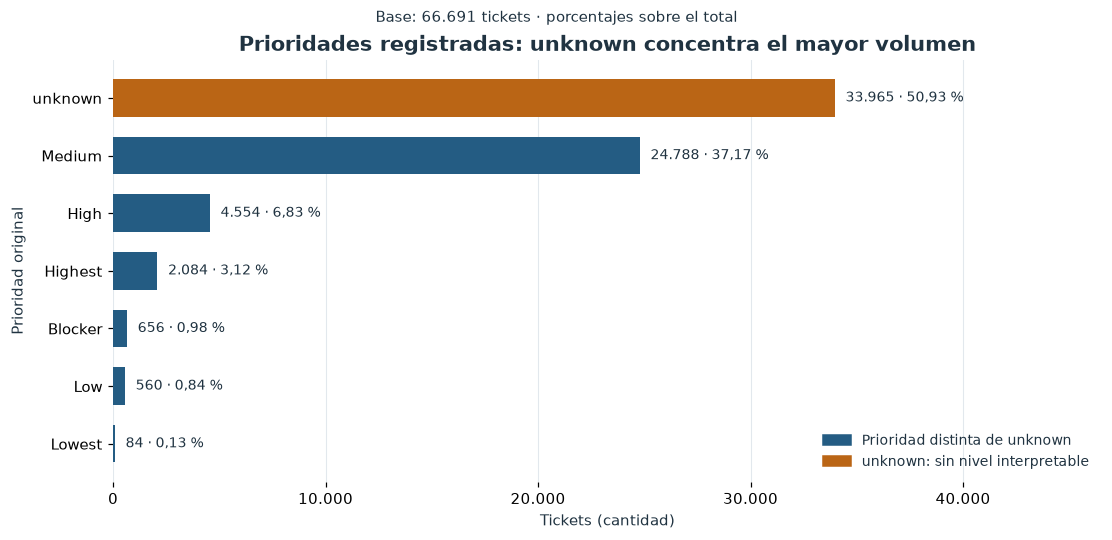

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
colores = [PALETA["naranja"] if categoria == "unknown" else PALETA["azul"]
           for categoria in prioridades.index]
barras = ax.barh(prioridades.index, prioridades["Tickets"], color=colores, height=0.65)
ax.invert_yaxis()
ax.bar_label(barras, labels=[f"{numero_es(n)} · {numero_es(p, 2)} %"
                            for n, p in zip(prioridades["Tickets"], prioridades["Porcentaje (%)"])],
             padding=7, fontsize=9)
ax.set_xlim(0, prioridades["Tickets"].max() * 1.37)
ax.set(title="Prioridades registradas: unknown concentra el mayor volumen",
       xlabel="Tickets (cantidad)", ylabel="Prioridad original")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: numero_es(x)))
ax.grid(axis="x")
ax.legend(handles=[Patch(color=PALETA["azul"], label="Prioridad distinta de unknown"),
                   Patch(color=PALETA["naranja"], label="unknown: sin nivel interpretable")],
          loc="lower right", frameon=False, fontsize=9)
fig.suptitle(f"Base: {numero_es(len(tickets))} tickets · porcentajes sobre el total", fontsize=10)
plt.show()
plt.close(fig)

In [12]:
n_unknown = int(prioridades.loc["unknown", "Tickets"])
n_medium = int(prioridades.loc["Medium", "Tickets"])
con_prioridad_interpretable = len(tickets) - n_unknown
p_medium_conocida = 100 * n_medium / con_prioridad_interpretable
display(Markdown(
    f"**Lectura del gráfico.** `unknown` representa **{numero_es(100 * n_unknown / len(tickets), 2)} %** "
    f"y `Medium`, **{numero_es(100 * n_medium / len(tickets), 2)} %** del total. "
    f"Entre los {numero_es(con_prioridad_interpretable)} tickets distintos de `unknown`, "
    f"`Medium` representa {numero_es(p_medium_conocida, 2)} %. Este último porcentaje cambia el denominador.\n\n"
    "**Interpretación y límite.** La clasificación disponible cubre parcialmente la criticidad. "
    "`unknown` no equivale a prioridad baja. Las frecuencias no prueban urgencia ni causas de demora. "
    "Conviene revisar la clasificación por proyecto, tipo y cohorte antes de proponer reglas operativas."
))

**Lectura del gráfico.** `unknown` representa **50,93 %** y `Medium`, **37,17 %** del total. Entre los 32.726 tickets distintos de `unknown`, `Medium` representa 75,74 %. Este último porcentaje cambia el denominador.

**Interpretación y límite.** La clasificación disponible cubre parcialmente la criticidad. `unknown` no equivale a prioridad baja. Las frecuencias no prueban urgencia ni causas de demora. Conviene revisar la clasificación por proyecto, tipo y cohorte antes de proponer reglas operativas.

## 7. Distribución por resolución

Se conserva `Done` separado de `Won't Do`, `Duplicate` y `Cannot Reproduce`. Sólo para presentar la tabla y el gráfico, el nulo se etiqueta **«Sin resolución registrada»**; no se reemplaza en los datos originales. El denominador sigue siendo el total de tickets, incluidos los nulos.

El estado final (`issue_status`) y la resolución (`issue_resolution`) son columnas distintas. Una etiqueta de resolución `Done` no demuestra satisfacción del usuario, resolución al primer contacto ni cumplimiento de SLA.

In [13]:
resoluciones = frecuencias(tickets["issue_resolution"], "Resolución")
validar_distribucion(resoluciones, "E", "Resoluciones")
mostrar_tabla(resoluciones.reset_index())

Resolución,Tickets,Porcentaje (%)
Done,62.034,93.017049
Won't Do,2.991,4.484863
Sin resolución registrada,853,1.279033
Duplicate,661,0.991138
Cannot Reproduce,152,0.227917


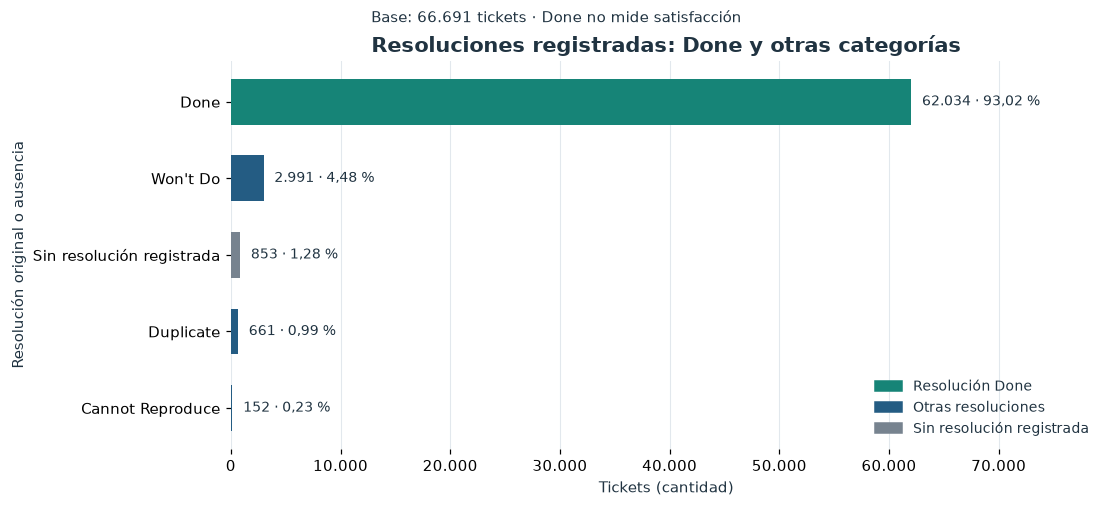

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
colores_resolucion = [PALETA["verde"] if categoria == "Done" else
                      PALETA["gris"] if categoria == "Sin resolución registrada" else PALETA["azul"]
                      for categoria in resoluciones.index]
barras = ax.barh(resoluciones.index, resoluciones["Tickets"], color=colores_resolucion, height=0.6)
ax.invert_yaxis()
ax.bar_label(barras, labels=[f"{numero_es(n)} · {numero_es(p, 2)} %"
                            for n, p in zip(resoluciones["Tickets"], resoluciones["Porcentaje (%)"])],
             padding=7, fontsize=9)
ax.set_xlim(0, resoluciones["Tickets"].max() * 1.28)
ax.set(title="Resoluciones registradas: Done y otras categorías",
       xlabel="Tickets (cantidad)", ylabel="Resolución original o ausencia")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: numero_es(x)))
ax.grid(axis="x")
ax.legend(handles=[Patch(color=PALETA["verde"], label="Resolución Done"),
                   Patch(color=PALETA["azul"], label="Otras resoluciones"),
                   Patch(color=PALETA["gris"], label="Sin resolución registrada")],
          loc="lower right", frameon=False, fontsize=9)
fig.suptitle(f"Base: {numero_es(len(tickets))} tickets · Done no mide satisfacción", fontsize=10)
plt.show()
plt.close(fig)

In [15]:
n_done = int(resoluciones.loc["Done", "Tickets"])
n_sin_resolucion = int(tickets["issue_resolution"].isna().sum())
n_otras = len(tickets) - n_done - n_sin_resolucion
cerrados_sin_resolucion = int((tickets["issue_status"].isin(["closed", "done"])
                             & tickets["issue_resolution"].isna()).sum())
display(Markdown(
    f"**Lectura del gráfico.** `Done` aparece en **{numero_es(n_done)} tickets "
    f"({numero_es(100 * n_done / len(tickets), 2)} %)**. Hay {numero_es(n_otras)} con otras resoluciones "
    f"y {numero_es(n_sin_resolucion)} sin resolución registrada.\n\n"
    f"**Límite de interpretación.** {numero_es(cerrados_sin_resolucion)} tickets tienen estado final "
    "`closed` o `done` y resolución ausente. No se intercambian ambas columnas ni se equiparan sus etiquetas "
    "a éxito percibido. Antes de proponer indicadores de satisfacción se requiere una fuente específica."
))
cruce_sql = tabla_sql("K")
referencia_cierre_sin_resolucion = int(pd.to_numeric(cruce_sql.loc[
    cruce_sql["estado"].isin(["closed", "done"]) & cruce_sql["resolucion"].eq("(NULL)"), "cantidad"
]).sum())
verificar("Estado y resolución", cerrados_sin_resolucion == referencia_cierre_sin_resolucion,
          "Consulta K; closed/done con resolución ausente")

**Lectura del gráfico.** `Done` aparece en **62.034 tickets (93,02 %)**. Hay 3.804 con otras resoluciones y 853 sin resolución registrada.

**Límite de interpretación.** 220 tickets tienen estado final `closed` o `done` y resolución ausente. No se intercambian ambas columnas ni se equiparan sus etiquetas a éxito percibido. Antes de proponer indicadores de satisfacción se requiere una fuente específica.

## 8. Evolución temporal

### Cobertura real y períodos parciales

Se agrupa por **fecha de creación UTC**, no por resolución ni por fecha de evento. La cobertura se calcula desde los archivos: no se recorta a 2016 para hacerla coincidir con la descripción del proveedor. El corte observado es el máximo de creación, resolución, último cambio y eventos; no es una fecha certificada de extracción.

Un período se marca parcial si su inicio precede a la primera creación o si su fin supera el corte observado. «Completo en calendario» no garantiza cobertura uniforme del sistema ni seguimiento completo de los tickets.

In [16]:
fecha_creacion = analisis["issue_created"]
ultimo_cambio = pd.to_datetime(tickets["last_change_date"], utc=True, format="ISO8601", errors="raise")
inicio = fecha_creacion.min()
corte = max(fecha_creacion.max(), analisis["issue_resolution_date"].max(),
            ultimo_cambio.max(), creacion_eventos.max())
mostrar_tabla(pd.DataFrame([
    {"Referencia": "Primera creación", "Fecha UTC": inicio.isoformat()},
    {"Referencia": "Última creación", "Fecha UTC": fecha_creacion.max().isoformat()},
    {"Referencia": "Primer evento", "Fecha UTC": creacion_eventos.min().isoformat()},
    {"Referencia": "Último evento", "Fecha UTC": creacion_eventos.max().isoformat()},
    {"Referencia": "Corte observado", "Fecha UTC": corte.isoformat()},
]))

ref_cobertura = tabla_sql("L")
coincide_cobertura = True
for campo, serie in [("issues.issue_created", fecha_creacion), ("history.created", creacion_eventos)]:
    ref = ref_cobertura.set_index("campo").loc[campo]
    coincide_cobertura &= (serie.min() == pd.Timestamp(ref["minimo_utc"]) and
                           serie.max() == pd.Timestamp(ref["maximo_utc"]) and
                           int(serie.lt("2016-01-01").sum()) == int(ref["antes_2016"]) and
                           int(serie.ge("2023-04-01").sum()) == int(ref["desde_abril_2023"]) and
                           int(serie.isna().sum()) == int(ref["fechas_null"]))
verificar("Cobertura temporal SQL", coincide_cobertura, "Consulta L; extremos, ausencias y límites documentados")
n_anteriores = int(fecha_creacion.lt("2016-01-01").sum())
display(Markdown(
    f"**Diferencia documental conservada:** {numero_es(n_anteriores)} tickets "
    f"({numero_es(100 * n_anteriores / len(tickets), 2)} %) fueron creados antes de 2016. "
    "Los eventos comienzan más tarde que las primeras creaciones. No se conoce la causa de esa cobertura; "
    "no se infiere una migración ni se eliminan los registros anteriores."
))

Referencia,Fecha UTC
Primera creación,2007-04-15T08:12:11+00:00
Última creación,2023-03-14T14:00:32+00:00
Primer evento,2015-08-12T11:14:28+00:00
Último evento,2023-03-14T14:19:32+00:00
Corte observado,2023-03-14T14:19:32+00:00


**Diferencia documental conservada:** 23.717 tickets (35,56 %) fueron creados antes de 2016. Los eventos comienzan más tarde que las primeras creaciones. No se conoce la causa de esa cobertura; no se infiere una migración ni se eliminan los registros anteriores.

### Tickets por año

Se cuentan las creaciones y se informa su porcentaje del total. El primer y último año se distinguen visualmente como parciales; no se anualiza su volumen.

In [17]:
anuales = fecha_creacion.dt.year.value_counts().sort_index().rename("Tickets").to_frame()
anuales["Porcentaje (%)"] = 100 * anuales["Tickets"] / len(tickets)
anuales.index.name = "Año"
inicio_anios = pd.to_datetime(anuales.index.astype(str) + "-01-01", utc=True)
fin_anios = pd.to_datetime(anuales.index.astype(str) + "-12-31", utc=True)
parcial_anual = (inicio_anios < inicio.normalize()) | (fin_anios > corte.normalize())
anuales["Cobertura"] = np.where(parcial_anual, "Parcial", "Calendario completo observado")
validar_distribucion(anuales, "F", "Años")
mostrar_tabla(anuales.reset_index())

Año,Tickets,Porcentaje (%),Cobertura
2.007,457,"0,69",Parcial
2.008,1.103,"1,65",Calendario completo observado
2.009,2.157,"3,23",Calendario completo observado
2.010,3.133,"4,70",Calendario completo observado
2.011,2.966,"4,45",Calendario completo observado
2.012,3.071,"4,60",Calendario completo observado
2.013,2.442,"3,66",Calendario completo observado
2.014,2.845,"4,27",Calendario completo observado
2.015,5.543,"8,31",Calendario completo observado
2.016,7.053,"10,58",Calendario completo observado


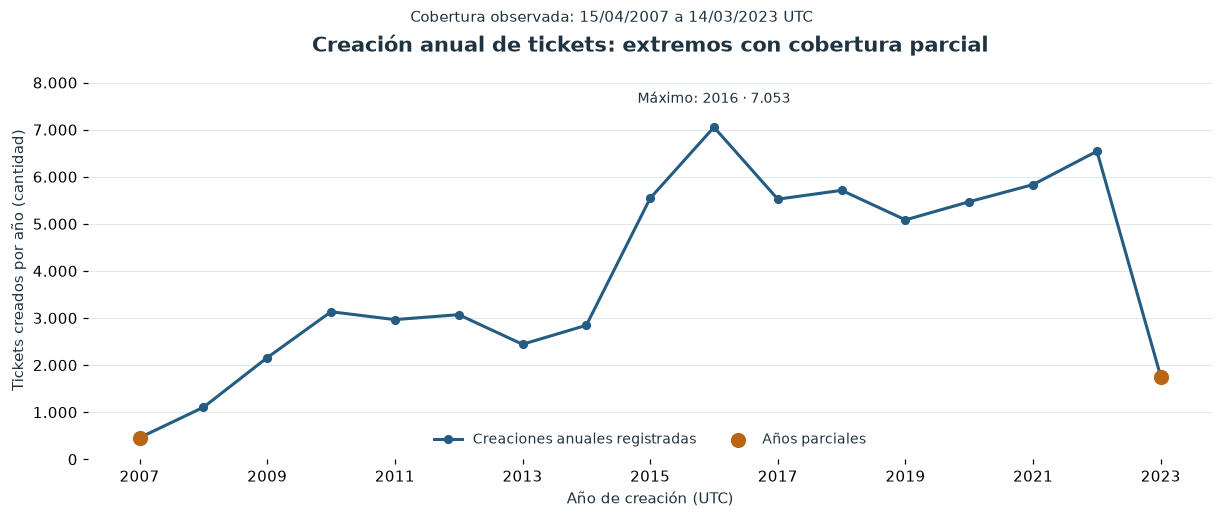

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
ax.plot(anuales.index, anuales["Tickets"], color=PALETA["azul"], marker="o", linewidth=2,
        markersize=5, label="Creaciones anuales registradas")
ax.scatter(anuales.index[parcial_anual], anuales.loc[parcial_anual, "Tickets"],
           color=PALETA["naranja"], s=80, zorder=4, label="Años parciales")
anio_maximo = int(anuales["Tickets"].idxmax())
ax.annotate(f"Máximo: {anio_maximo} · {numero_es(anuales.loc[anio_maximo, 'Tickets'])}",
            xy=(anio_maximo, anuales.loc[anio_maximo, "Tickets"]), xytext=(0, 16),
            textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Creación anual de tickets: extremos con cobertura parcial",
       xlabel="Año de creación (UTC)", ylabel="Tickets creados por año (cantidad)", ylim=(0, anuales["Tickets"].max() * 1.2))
ax.set_xticks(anuales.index[::2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: numero_es(x)))
ax.grid(axis="y")
ax.legend(loc="lower center", frameon=False, ncol=2, fontsize=9)
fig.suptitle(f"Cobertura observada: {inicio:%d/%m/%Y} a {corte:%d/%m/%Y} UTC", fontsize=10)
plt.show()
plt.close(fig)

### Tickets por mes

La clave `AAAA-MM` evita mezclar el mismo mes de años diferentes. Se construye una rejilla mensual desde el inicio al corte y se comprueba que cada mes tenga registros. Si aparecieran meses ausentes, se conservarían como huecos: no se imputan ceros sin evidencia de cobertura.

La tabla muestra sólo los últimos seis meses, pero la validación compara **todos** los meses y el gráfico utiliza la serie completa. Las franjas naranjas señalan los meses parciales de los extremos.

In [19]:
conteo_meses = fecha_creacion.dt.strftime("%Y-%m").value_counts().sort_index()
rejilla_meses = pd.period_range(inicio.strftime("%Y-%m"), corte.strftime("%Y-%m"), freq="M").astype(str)
mensuales = conteo_meses.reindex(rejilla_meses).rename("Tickets").to_frame()
mensuales.index.name = "Mes"
verificar("Rejilla mensual", mensuales["Tickets"].notna().all(),
          f"{len(mensuales)} meses con registros; no se imputaron ceros")
mensuales["Porcentaje (%)"] = 100 * mensuales["Tickets"] / len(tickets)
inicios_mes = pd.to_datetime(mensuales.index + "-01", utc=True)
fines_mes = inicios_mes + pd.offsets.MonthEnd(0)
parcial_mensual = (inicios_mes < inicio.normalize()) | (fines_mes > corte.normalize())
mensuales["Cobertura"] = np.where(parcial_mensual, "Parcial", "Calendario completo observado")
validar_distribucion(mensuales, "G", "Meses")
mostrar_tabla(mensuales.tail(6).reset_index())

Mes,Tickets,Porcentaje (%),Cobertura
2022-10,612,"0,92",Calendario completo observado
2022-11,633,"0,95",Calendario completo observado
2022-12,629,"0,94",Calendario completo observado
2023-01,749,"1,12",Calendario completo observado
2023-02,663,"0,99",Calendario completo observado
2023-03,343,"0,51",Parcial


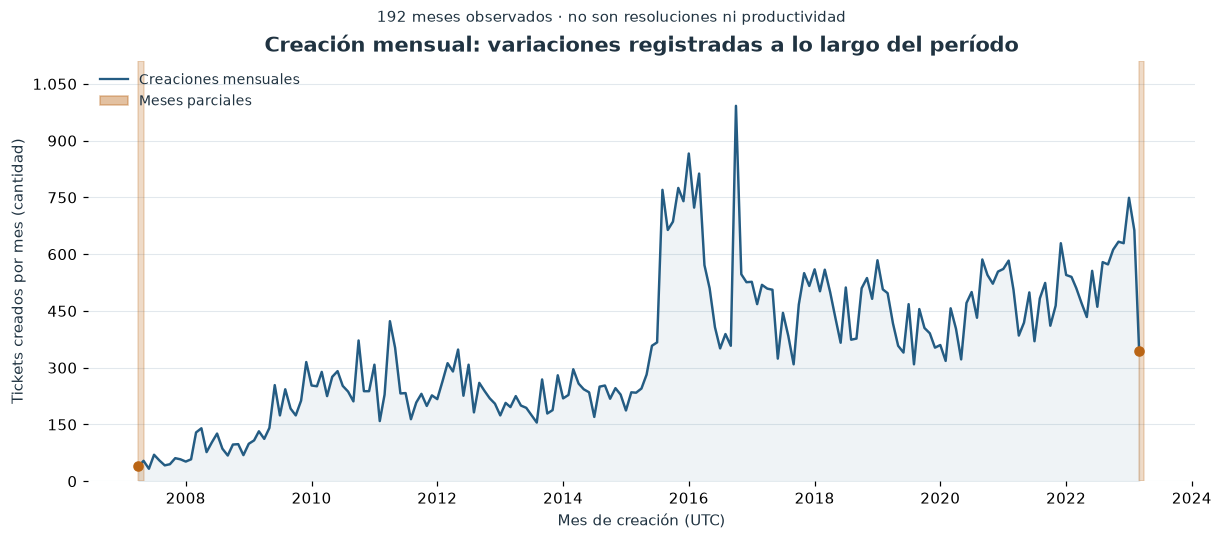

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
fechas_meses = pd.to_datetime(mensuales.index + "-01")
ax.plot(fechas_meses, mensuales["Tickets"], color=PALETA["azul"], linewidth=1.6,
        label="Creaciones mensuales registradas")
ax.fill_between(fechas_meses, mensuales["Tickets"].to_numpy(dtype=float),
                color=PALETA["azul"], alpha=0.07)
for posicion in np.flatnonzero(parcial_mensual):
    mes_inicio = fechas_meses[posicion]
    ax.axvspan(mes_inicio, mes_inicio + pd.offsets.MonthBegin(1),
               color=PALETA["naranja"], alpha=0.23)
ax.scatter(fechas_meses[parcial_mensual], mensuales.loc[parcial_mensual, "Tickets"],
           color=PALETA["naranja"], s=35, zorder=4)
ax.set(title="Creación mensual: variaciones registradas a lo largo del período",
       xlabel="Mes de creación (UTC)", ylabel="Tickets creados por mes (cantidad)",
       ylim=(0, mensuales["Tickets"].max() * 1.12))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: numero_es(x)))
ax.grid(axis="y")
ax.legend(handles=[plt.Line2D([], [], color=PALETA["azul"], label="Creaciones mensuales"),
                   Patch(color=PALETA["naranja"], alpha=0.4, label="Meses parciales")],
          loc="upper left", frameon=False, fontsize=9)
fig.suptitle(f"{len(mensuales)} meses observados · no son resoluciones ni productividad", fontsize=10)
plt.show()
plt.close(fig)

In [21]:
variacion_2022 = 100 * (anuales.loc[2022, "Tickets"] / anuales.loc[2021, "Tickets"] - 1)
display(Markdown(
    f"**Lectura de las líneas.** El máximo anual es {anio_maximo}, con "
    f"{numero_es(anuales.loc[anio_maximo, 'Tickets'])} creaciones. En 2022 se registraron "
    f"{numero_es(anuales.loc[2022, 'Tickets'])}, un {numero_es(variacion_2022, 2)} % más que en 2021. "
    "El año 2023 y su último mes son parciales, por lo que no deben compararse como períodos completos.\n\n"
    "**Interpretación y límite.** Las variaciones describen registros de creación. Pueden coexistir cambios "
    "en cobertura, mezcla de proyectos o prácticas de registro; no se ha identificado su causa. "
    "Las series no reconstruyen backlog, no demuestran estacionalidad y no miden productividad. "
    "Se recomienda comparar períodos equivalentes y segmentos semejantes."
))

**Lectura de las líneas.** El máximo anual es 2016, con 7.053 creaciones. En 2022 se registraron 6.542, un 12,14 % más que en 2021. El año 2023 y su último mes son parciales, por lo que no deben compararse como períodos completos.

**Interpretación y límite.** Las variaciones describen registros de creación. Pueden coexistir cambios en cobertura, mezcla de proyectos o prácticas de registro; no se ha identificado su causa. Las series no reconstruyen backlog, no demuestran estacionalidad y no miden productividad. Se recomienda comparar períodos equivalentes y segmentos semejantes.

## 9. Hallazgos principales

### Resultados calculados en esta ejecución

Los valores siguientes se derivan de las tablas anteriores, sin copiar constantes de los informes para producir resultados. Los informes se utilizan como referencia independiente de conciliación.

In [22]:
n_anomalias = int(flags_tickets["dq_has_problem"].sum())
hallazgos = pd.DataFrame([
    {"Hallazgo": "Prioridad unknown", "Resultado": f"{numero_es(n_unknown)} · {numero_es(100*n_unknown/len(tickets), 2)} %",
     "Interpretación": "La criticidad no es interpretable en todo el conjunto"},
    {"Hallazgo": "Resolución Done", "Resultado": f"{numero_es(n_done)} · {numero_es(100*n_done/len(tickets), 2)} %",
     "Interpretación": "Clasificación registrada; no equivale a satisfacción"},
    {"Hallazgo": "Máximo anual", "Resultado": f"{anio_maximo}: {numero_es(anuales.loc[anio_maximo, 'Tickets'])}",
     "Interpretación": "Volumen de creaciones, no productividad"},
    {"Hallazgo": "Tickets con anomalías", "Resultado": f"{numero_es(n_anomalias)} · {numero_es(100*n_anomalias/len(tickets), 4)} %",
     "Interpretación": "Unión de condiciones que pueden solaparse"},
    {"Hallazgo": "Sin historial", "Resultado": numero_es(sin_historial),
     "Interpretación": "Sin eventos observados; no implica ausencia de trabajo"},
    {"Hallazgo": "Cobertura histórica", "Resultado": "Tickets desde 2007; eventos desde 2015",
     "Interpretación": "Los dos archivos no cubren igual toda la historia"},
])
mostrar_tabla(hallazgos)

Hallazgo,Resultado,Interpretación
Prioridad unknown,"33.965 · 50,93 %",La criticidad no es interpretable en todo el conjunto
Resolución Done,"62.034 · 93,02 %",Clasificación registrada; no equivale a satisfacción
Máximo anual,2016: 7.053,"Volumen de creaciones, no productividad"
Tickets con anomalías,"450 · 0,6748 %",Unión de condiciones que pueden solaparse
Sin historial,41,Sin eventos observados; no implica ausencia de trabajo
Cobertura histórica,Tickets desde 2007; eventos desde 2015,Los dos archivos no cubren igual toda la historia


### Conciliación e integridad

Cada control comprueba una propiedad verificable, como todos los grupos de una distribución o todos los flags de un archivo. El resumen se divide en bloques pequeños para evitar tablas masivas. Los gráficos utilizan las mismas tablas conciliadas.

La integridad SHA-256 demuestra que este análisis no alteró los dos CSV procesados durante su ejecución. La conciliación contrasta una extracción local con **informes SQL existentes**; no certifica el estado actual del servidor ni requiere conectarse a él.

In [23]:
for nombre, ruta in ARCHIVOS.items():
    verificar(f"{nombre}: integridad SHA-256", huella(ruta) == huellas_iniciales[nombre],
              "Archivo procesado idéntico antes y después")
resumen_controles = pd.DataFrame(controles)
for desplazamiento in range(0, len(resumen_controles), 12):
    mostrar_tabla(resumen_controles.iloc[desplazamiento:desplazamiento + 12])
print(f"Resultado: {len(controles)} controles superados. No se encontraron discrepancias numéricas.")

Control,Estado,Alcance
Volúmenes SQL,SUPERADA,Consulta A; tickets y eventos separados
Cobertura SQL,SUPERADA,Consulta I; al menos un evento
Claves e integridad,SUPERADA,Columnas originales; IDs; eventos sin ticket padre
Tickets: valores de flags,SUPERADA,35 columnas booleanas documentadas
Eventos: valores de flags,SUPERADA,17 columnas booleanas documentadas
Tickets: flags de calidad,SUPERADA,Todos los flags de data_quality.md
Tickets: flags SQL,SUPERADA,Consulta J; todos los flags
Tickets: ausencias,SUPERADA,58 columnas originales; data_quality.md
Eventos: flags de calidad,SUPERADA,Todos los flags de data_quality.md
Eventos: flags SQL,SUPERADA,Consulta J; todos los flags


Control,Estado,Alcance
Prioridades: porcentajes SQL,SUPERADA,"Tolerancia: 0,00005 puntos porcentuales"
Resoluciones: conteos SQL,SUPERADA,5 grupos; consulta E
Resoluciones: porcentajes SQL,SUPERADA,"Tolerancia: 0,00005 puntos porcentuales"
Estado y resolución,SUPERADA,Consulta K; closed/done con resolución ausente
Cobertura temporal SQL,SUPERADA,"Consulta L; extremos, ausencias y límites documentados"
Años: conteos SQL,SUPERADA,17 grupos; consulta F
Años: porcentajes SQL,SUPERADA,"Tolerancia: 0,00005 puntos porcentuales"
Rejilla mensual,SUPERADA,192 meses con registros; no se imputaron ceros
Meses: conteos SQL,SUPERADA,192 grupos; consulta G
Meses: porcentajes SQL,SUPERADA,"Tolerancia: 0,00005 puntos porcentuales"


Resultado: 24 controles superados. No se encontraron discrepancias numéricas.


### Limitaciones y discrepancias documentadas

- **Discrepancia de cobertura documental:** `FEATURES.md` describe tickets desde 2016, pero el archivo contiene creaciones desde 2007. El historial comienza en 2015. Se conserva la diferencia y no se atribuye a una migración u otra causa sin evidencia.
- **Sin discrepancias numéricas en las conciliaciones:** los resultados exploratorios calculados coinciden con las tablas de referencia. Las anomalías existentes, incluidos negativos y discrepancias de duración, se conservan; que un cálculo coincida no significa que todo dato sea semánticamente correcto.
- **Ausencias y solapamientos:** nulo no siempre significa error y los flags no son categorías mutuamente excluyentes. Sus conteos no deben sumarse como tickets distintos.
- **Poblaciones heterogéneas:** los tipos y proyectos pueden representar procesos diferentes. `unknown` se mantiene separado y no se interpreta como prioridad baja.
- **Períodos y seguimiento:** 2007 y 2023 son parciales; los tickets recientes pueden no tener una resolución observada al corte. No se calcula una tasa de resolución por cohorte ni se corrige censura en este notebook.
- **Tiempo y resultados de negocio:** no se calculan aquí tiempos de resolución ni esfuerzo laboral. Los tiempos calendario y acumulados del proyecto no equivalen a horas trabajadas. `Done` no mide satisfacción ni SLA.
- **Alcance descriptivo:** no se prueban relaciones causales, estacionalidad ni efectos de intervenciones. Tampoco se auditan las fórmulas o visuales del dashboard.

## 10. Conclusiones del análisis exploratorio

El análisis conserva los dos niveles de información —tickets y eventos— y produce una lectura verificable de calidad, prioridades, resoluciones y volumen temporal. La conciliación con los informes SQL y las huellas de integridad permiten seguir el resultado desde los CSV sin duplicar la limpieza ni cambiar la evidencia.

La clasificación `unknown` limita la interpretación de criticidad, la resolución `Done` describe una categoría del sistema y las líneas temporales exigen atención a períodos parciales y cobertura desigual. Las anomalías y los nulos se documentan por su significado y población, en lugar de ocultarlos para obtener indicadores más favorables.

Como líneas de revisión se propone aclarar criterios de prioridad, estudiar la cobertura de los registros antiguos y revisar anomalías por ID dentro de un entorno autorizado, sin publicar identificadores en este notebook. Las comparaciones operativas futuras deberían mantener segmentos y seguimiento equivalentes. **Estas recomendaciones no fueron implementadas ni evaluadas en una empresa real.**

El [informe final](../reports/final_analysis.md) desarrolla tiempos calendario, reaperturas y duraciones por estado con sus limitaciones. Esta entrega incorpora únicamente el primer notebook exploratorio.

**Reproducción:** consulta [la guía de notebooks](README.md). Reinicia el kernel, selecciona `.venv`, ejecuta todo y revisa la tabla de validaciones antes de guardar nuevas salidas.